# 01 – EDA and Modeling Decisions

End-to-end exploratory data analysis (EDA) and key modeling decisions for the *Credit Card Fraud Detection* dataset (Kaggle: `mlg-ulb/creditcardfraud`).

This notebook is designed to run **end-to-end** once `data/raw/creditcard.csv` is available.


## A) Business Framing and Anomaly Detection Perspective

- **Business goal**: Detect fraudulent credit card transactions early so they can be blocked or investigated.
- **Operational constraint**: Fraud is rare but costly; we must balance catching as many frauds as possible with avoiding excessive false alarms.
- **Modeling view**: Treat fraud detection as **anomaly detection** on transaction features:
  - Train unsupervised / one-class models on normal transactions.
  - Use the learned notion of normal to assign anomaly scores to new transactions.

Key implications:
- Majority of transactions are legitimate; models must be robust to extreme class imbalance.
- False negatives (missed fraud) are typically more costly than false positives, but both matter.
- We emphasize **ranking quality** (PR-AUC, ROC-AUC) and **thresholded performance** (precision/recall/F1).


In [4]:
import sys
from pathlib import Path

# Point ROOT to the project root (one level up from notebooks/)
ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [5]:
# Setup: imports, paths, and reproducibility

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from shared.utils import set_global_seed
from ml import preprocess as ml_preprocess

# Build DATA_PATH relative to project root
DATA_PATH = ROOT / "data" / "raw" / "creditcard.csv"

set_global_seed(42)
plt.style.use("default")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Expected dataset at {DATA_PATH}. Please download it first."
    )

df = ml_preprocess.load_raw_data(DATA_PATH)
df.head()


2026-01-25 00:29:14,986 | INFO | fraud_anomaly_lab | Loading raw data from D:\Project\fraud-anomaly-lab\data\raw\creditcard.csv
2026-01-25 00:29:15,886 | INFO | fraud_anomaly_lab | Schema validation passed: required columns present and target is binary.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## B) Dataset Facts and Class Imbalance

The Kaggle dataset contains European credit card transactions from September 2013.

We summarize basic facts and quantify the imbalance in the `Class` label (1 = fraud, 0 = non-fraud).


In [6]:
# Basic shape and class distribution
n_rows, n_cols = df.shape
class_counts = df['Class'].value_counts().sort_index()
class_frac = df['Class'].value_counts(normalize=True).sort_index() * 100

print(f'Rows: {n_rows}, Columns: {n_cols}')
print('Class distribution (counts):')
print(class_counts)
print('\nClass distribution (%):')
print(class_frac.round(4))

fraud_rate = class_frac.loc[1]
print(f'\nEstimated fraud rate: {fraud_rate:.4f}% of transactions are fraud.')


Rows: 284807, Columns: 31
Class distribution (counts):
Class
0    284315
1       492
Name: count, dtype: int64

Class distribution (%):
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64

Estimated fraud rate: 0.1727% of transactions are fraud.


## C) Feature Overview and Data Quality Checks

Columns:

- `Time`: Seconds elapsed between this transaction and the first transaction in the dataset.
- `Amount`: Transaction amount (Euro).
- `Class`: Target label (1 = fraud, 0 = non-fraud).
- `V1`–`V28`: Numeric features derived via PCA for confidentiality.

We verify data types and check for missing values.


In [7]:
# Data types and missing values
print('Column dtypes:\n')
print(df.dtypes)

print('\nMissing values per column:\n')
missing = df.isnull().sum()
print(missing[missing > 0] if (missing > 0).any() else 'No missing values detected.')


Column dtypes:

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Missing values per column:

No missing values detected.


## D) Leakage-Safe Time-Based Split

We want to mimic a real-world scenario where models are trained on past data and evaluated on future data.

Strategy:

- Sort by `Time` in ascending order.
- Split into:
  - Train: 60% of earliest transactions.
  - Validation: next 20%.
  - Test: final 20%.
- Ensure no future information leaks into the past via random shuffling.

We reuse the time-based split logic from `ml.preprocess.time_based_split` to stay consistent with the training pipeline.


In [8]:
# Time-based split using the shared preprocessing utility
train_df, val_df, test_df = ml_preprocess.time_based_split(
    df,
    train_ratio=0.6,
    val_ratio=0.2,
    test_ratio=0.2,
    sort_by='Time',
)

print('Split sizes:')
print({'train': len(train_df), 'val': len(val_df), 'test': len(test_df)})

def summarize_time(split_df, name):
    print(f'{name} Time range: {split_df["Time"].min()} -> {split_df["Time"].max()}')

summarize_time(train_df, 'Train')
summarize_time(val_df, 'Val')
summarize_time(test_df, 'Test')


2026-01-25 00:29:23,861 | INFO | fraud_anomaly_lab | Time-based split complete: train=170884, val=56961, test=56962.
2026-01-25 00:29:23,863 | INFO | fraud_anomaly_lab | Train Time range: [0.0, 120396.0]
2026-01-25 00:29:23,864 | INFO | fraud_anomaly_lab | Val Time range: [120396.0, 145247.0]
2026-01-25 00:29:23,865 | INFO | fraud_anomaly_lab | Test Time range: [145248.0, 172792.0]


Split sizes:
{'train': 170884, 'val': 56961, 'test': 56962}
Train Time range: 0.0 -> 120396.0
Val Time range: 120396.0 -> 145247.0
Test Time range: 145248.0 -> 172792.0


### Time Distribution Across Splits

We visualize how transactions (especially frauds) are distributed over time across train/validation/test splits.


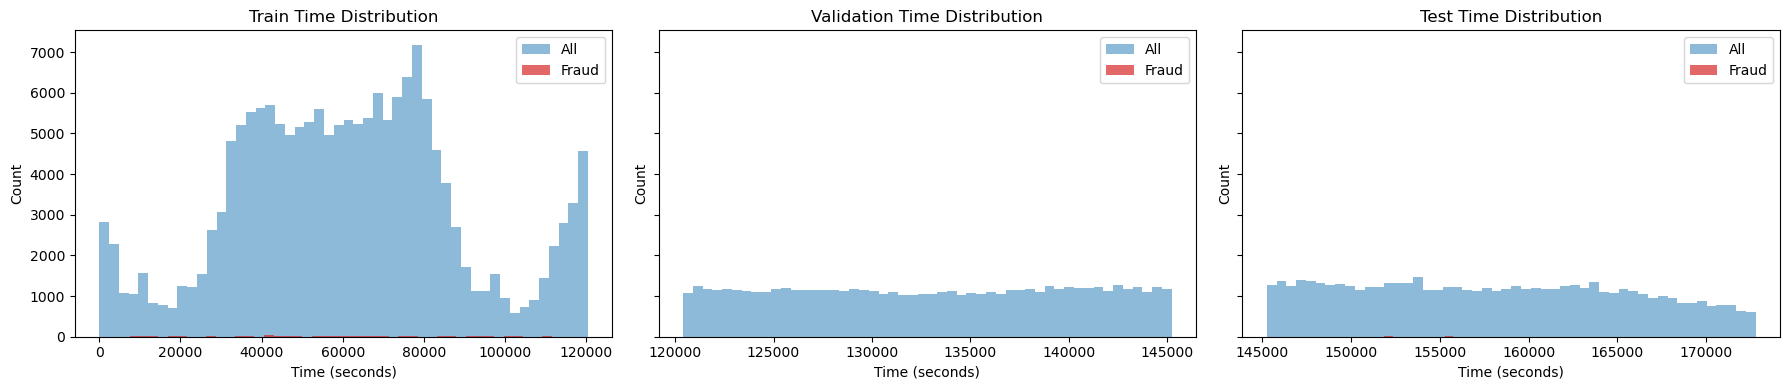

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)

for ax, split_df, title in zip(
    axes,
    [train_df, val_df, test_df],
    ['Train', 'Validation', 'Test'],
):
    fraud_times = split_df.loc[split_df['Class'] == 1, 'Time']
    ax.hist(split_df['Time'], bins=50, alpha=0.5, label='All', color='tab:blue')
    if not fraud_times.empty:
        ax.hist(
            fraud_times,
            bins=50,
            alpha=0.7,
            label='Fraud',
            color='tab:red',
        )
    ax.set_title(f'{title} Time Distribution')
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Count')
    ax.legend()

plt.tight_layout()
plt.show()


## E) Distribution Plots

We inspect key distributions to understand differences between fraud and non-fraud transactions.

Focus:
- `Amount` distribution (with log scale) by class.
- `Time` distribution of frauds.
- PCA components (V1–V28) summary statistics.


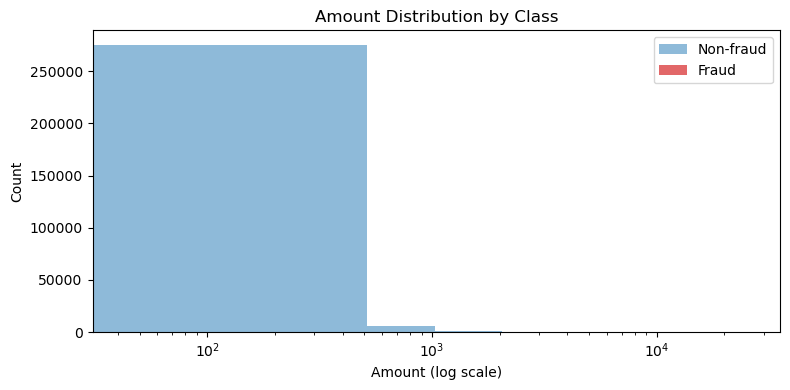

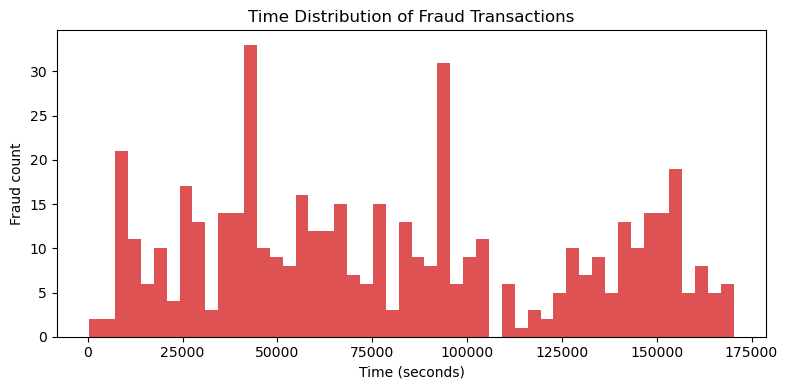

,count,mean,std,min,25%,50%,75%,max
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666


In [10]:
# Amount distribution by class (log-scaled x-axis)
fig, ax = plt.subplots(figsize=(8, 4))
non_fraud = df[df['Class'] == 0]['Amount']
fraud = df[df['Class'] == 1]['Amount']

ax.hist(non_fraud, bins=50, alpha=0.5, label='Non-fraud', color='tab:blue')
ax.hist(fraud, bins=50, alpha=0.7, label='Fraud', color='tab:red')
ax.set_xscale('log')
ax.set_xlabel('Amount (log scale)')
ax.set_ylabel('Count')
ax.set_title('Amount Distribution by Class')
ax.legend()
plt.tight_layout()
plt.show()

# Time distribution of frauds only
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df.loc[df['Class'] == 1, 'Time'], bins=50, color='tab:red', alpha=0.8)
ax.set_xlabel('Time (seconds)')
ax.set_ylabel('Fraud count')
ax.set_title('Time Distribution of Fraud Transactions')
plt.tight_layout()
plt.show()

# PCA components summary statistics
pca_cols = [f'V{i}' for i in range(1, 29)]
pca_summary = df[pca_cols].describe().T
pca_summary.head()


## F) Correlation Heatmap (PCA Features)

We examine correlations among PCA components. Since they are derived features,
correlation patterns may not map directly to interpretable business concepts,
but they still inform us about structure in the transformed feature space.


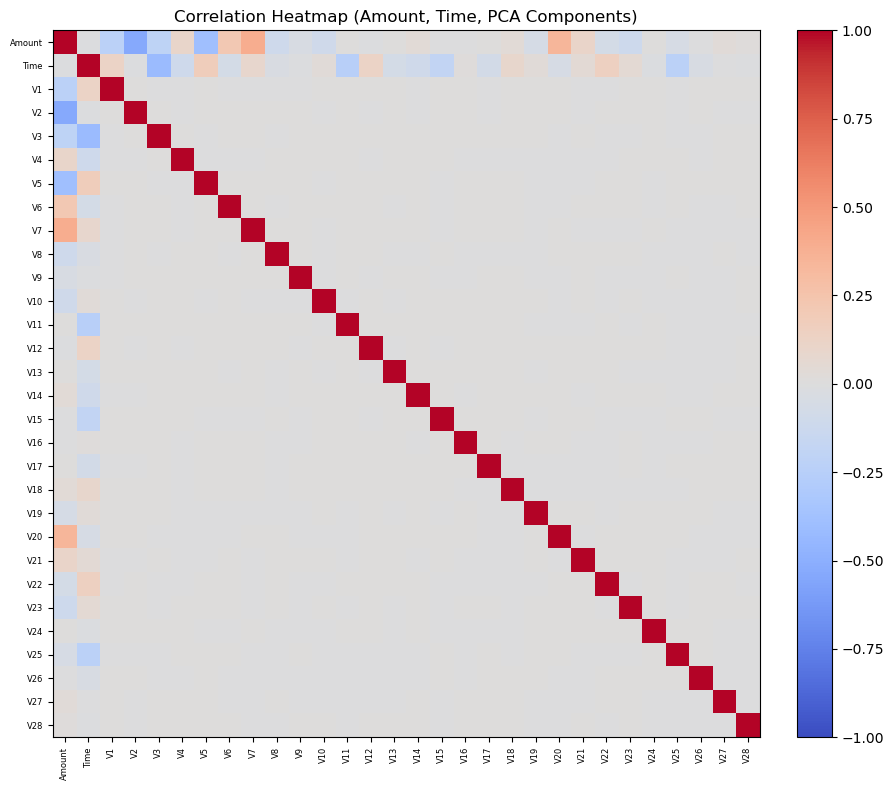

In [11]:
corr = df[['Amount', 'Time'] + [f'V{i}' for i in range(1, 29)]].corr()

fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_title('Correlation Heatmap (Amount, Time, PCA Components)')
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns, fontsize=6)
fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## G) Supervised Proxy for Feature Importance

Although our primary models are anomaly detectors trained only on normal data,
we can train a simple supervised proxy model using the `Class` labels to gain
insight into which PCA components appear most influential.

Caveats:

- PCA components (`V1`–`V28`) are linear combinations of original, hidden features.
- Importance on these components does not translate directly to actionable business features.
- Still, relative importance can inform which components to monitor.

We use:

- LogisticRegression with `class_weight='balanced'` as a supervised baseline.
- The same preprocessing as the anomaly models (RobustScaler on Time/Amount).
- `sklearn.inspection.permutation_importance` on the validation split.


In [12]:
# Build preprocessor and supervised proxy pipeline
feature_cols = [c for c in train_df.columns if c != 'Class']
preprocessor = ml_preprocess.build_preprocessor()

log_reg = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    n_jobs=-1,
)
proxy_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', log_reg),
])

proxy_pipeline.fit(train_df[feature_cols], train_df['Class'])

perm_result = permutation_importance(
    proxy_pipeline,
    val_df[feature_cols],
    val_df['Class'],
    n_repeats=5,
    random_state=42,
    scoring='roc_auc',
)

importances = pd.DataFrame(
    {
        'feature': feature_cols,
        'importance_mean': perm_result.importances_mean,
        'importance_std': perm_result.importances_std,
    }
).sort_values('importance_mean', ascending=False)

importances.head(15)


2026-01-25 00:29:29,136 | INFO | fraud_anomaly_lab | Preprocessor created with RobustScaler on columns: Amount, Time


,feature,importance_mean,importance_std
4,V4,0.032881,0.011402
29,Amount,0.031788,0.004221
14,V14,0.015403,0.004721
1,V1,0.009127,0.008872
6,V6,0.008396,0.004543
10,V10,0.007174,0.006178
16,V16,0.007106,0.002293
12,V12,0.006545,0.003114
5,V5,0.004762,0.003075
22,V22,0.004641,0.003748


The table above shows which components (Vx), along with `Time` and `Amount`,
contribute most to the supervised proxy's discrimination power.

In downstream monitoring, we will pay particular attention to:

- The most influential PCA components (by permutation importance).
- The distribution of `Amount` and `Time`.
- How these features shift over time and relate to predicted fraud scores.


## H) Metric Choice and Thresholding Strategy

Given the extreme class imbalance, we focus on metrics that emphasize the positive (fraud) class:

- ROC-AUC: ranking quality overall, but can remain high even if precision is low.
- PR-AUC (Precision–Recall AUC): more informative under heavy imbalance.
- Precision: of the transactions flagged as fraud, how many are truly fraud.
- Recall: of the truly fraudulent transactions, how many we catch.
- F1: harmonic mean of precision and recall at a given threshold.

Thresholding strategy for anomaly scores (see `context/METRICS.md` and `ml.evaluate.choose_threshold`):

- Use validation data to sweep possible thresholds on anomaly scores.
- Prefer thresholds that simultaneously achieve:
  - High precision (e.g., ≥ 0.90) to limit false alarms.
  - Reasonable recall (e.g., ≥ 0.75) to catch most frauds.
- If no threshold satisfies both constraints, choose the one with the best F1 and document the trade-off.


## I) Reproducibility

We ensure that experiments are reproducible by:

- Fixing random seeds across NumPy, Python's `random`, and model libraries via `shared.utils.set_global_seed`.
- Recording package versions and Python version.
- Using deterministic time-based splits (no shuffling).


In [13]:
import sys
import sklearn
import pyod

print('Python:', sys.version)
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('scikit-learn:', sklearn.__version__)
print('pyod:', pyod.__version__)


Python: 3.13.0 | packaged by conda-forge | (main, Nov 27 2024, 19:03:49) [MSC v.1942 64 bit (AMD64)]
pandas: 2.3.1
numpy: 2.2.6
scikit-learn: 1.7.1
pyod: 2.0.6


## J) What We Will Monitor in Production

To operate these models safely and effectively in production, we plan to monitor:

1. Prediction volume:
   - Number of scored transactions per unit time.
   - Breakdown by predicted class and score distribution.

2. Observed fraud rate:
   - Fraction of flagged transactions later confirmed as fraudulent (where labels are available).
   - Drift in observed fraud rate over time.

3. Latency:
   - End-to-end scoring latency per transaction.
   - Tail latencies (p95, p99) to ensure real-time constraints are met.

4. Data drift (planned):
   - Statistical tests (PSI, KS) for key features: `Amount`, `Time`, top PCA components.
   - Distribution of anomaly scores compared to training/validation baselines.

5. Model performance (where labels are available):
   - PR-AUC, ROC-AUC, precision, recall, and F1 on recent labeled windows.
   - Stability of calibrated thresholds and whether precision/recall constraints remain satisfied.

These monitoring signals will inform when to retrain models, adjust thresholds, or investigate upstream issues.
